# Introduccion a Tensor Flow

In [2]:
import tensorflow.compat.v1 as tf
tf.disable_eager_execution()

In [3]:
x1 = tf.constant([1,2,3,4,5])
x2 = tf.constant([6,7,8,9,10])

In [5]:
res = tf.multiply(x1,x2)
print(res)

Tensor("Mul_1:0", shape=(5,), dtype=int32)


In [6]:
sess = tf.Session()
print(sess.run(res))
sess.close()

[ 6 14 24 36 50]


In [7]:
with tf.Session() as sess:
    output = sess.run(res)
    print(output)

[ 6 14 24 36 50]


In [9]:
config = tf.ConfigProto(log_device_placement = True)
config = tf.ConfigProto(allow_soft_placement = True)

# Aprendizaje neuronal de las señales de trafico

In [41]:
from skimage import io
from skimage.transform import resize
import os
import numpy as np

In [67]:
def load_ml_data(data_directory):
    dirs = [d for d in os.listdir(data_directory)
           if os.path.isdir(os.path.join(data_directory, d))]
    labels = []
    images = []
    for d in dirs:
        label_dir = os.path.join(data_directory, d)
        file_names = [os.path.join(label_dir, f)
                     for f in os.listdir(label_dir)
                     if f.endswith(".ppm")]
        for f in file_names:
            # 1. Leemos la imagen
            img = io.imread(f)
            # 2. La redimensionamos para que todas tengan exactamente el mismo tamaño (ej. 32x32)
            img_resized = resize(img, (32, 32), anti_aliasing=True)
            
            images.append(img_resized)
            labels.append(int(d))
            
    #devolver ya convertidas a arrays de numpy
    return np.array(images), np.array(labels)

In [68]:
main_dir = "../datasets/belgian/"
train_data_dir = os.path.join(main_dir, "Training")
test_data_dir = os.path.join(main_dir, "Testing")

In [69]:
images, labels = load_ml_data(train_data_dir)

In [70]:
images.ndim

4

In [71]:
images.size

14054400

In [72]:
images[0]

array([[[0.7383261 , 0.7331186 , 0.60479338],
        [0.53486078, 0.41658458, 0.28938707],
        [0.53401528, 0.41186598, 0.2999125 ],
        ...,
        [0.19816991, 0.22695028, 0.15141601],
        [0.18932208, 0.21486816, 0.14210695],
        [0.19040475, 0.21689991, 0.14620292]],

       [[0.71056602, 0.68343009, 0.55966268],
        [0.49771239, 0.34813562, 0.23517245],
        [0.46365022, 0.31986319, 0.22354242],
        ...,
        [0.19123982, 0.22513238, 0.14751995],
        [0.19504198, 0.2354347 , 0.15918316],
        [0.20253625, 0.22976648, 0.16195415]],

       [[0.71377218, 0.69415478, 0.55315998],
        [0.53513943, 0.43681625, 0.31730658],
        [0.50567334, 0.40165334, 0.29073815],
        ...,
        [0.18783363, 0.21126019, 0.13894047],
        [0.19073348, 0.22743355, 0.15380383],
        [0.19808408, 0.22877371, 0.15982924]],

       ...,

       [[0.09451979, 0.12496416, 0.05043914],
        [0.07816191, 0.11032761, 0.06071432],
        [0.12457252, 0

In [73]:
labels.ndim

1

In [74]:
labels.size

4575

In [75]:
len(set(labels))

62

In [76]:
images.flags

  C_CONTIGUOUS : True
  F_CONTIGUOUS : False
  OWNDATA : True
  WRITEABLE : True
  ALIGNED : True
  WRITEBACKIFCOPY : False

In [77]:
images.itemsize

8

In [78]:
images.nbytes

112435200

In [79]:
images.nbytes/images.itemsize

14054400.0

In [80]:
import matplotlib.pyplot as plt

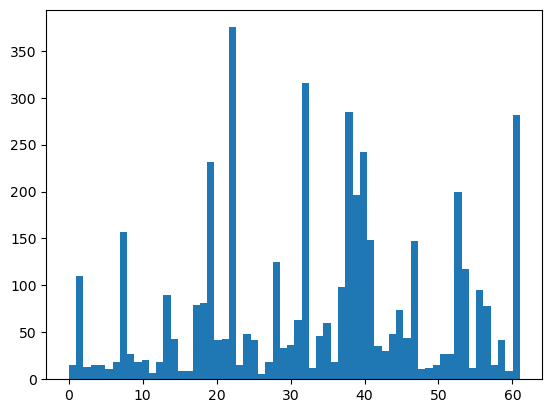

In [81]:
plt.hist(labels, len(set(labels)))
plt.show()

In [58]:
import random

In [82]:
rand_signs = random.sample(range(0, len(labels)), 6)
rand_signs

[1921, 3689, 2271, 2474, 1610, 646]

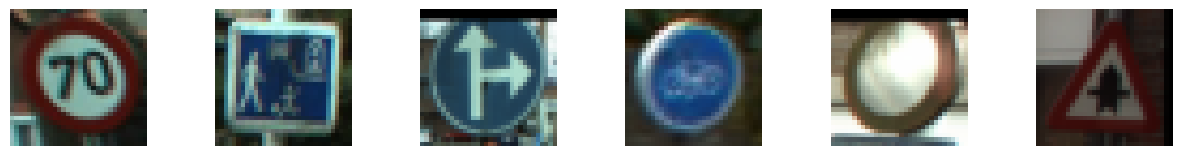

Muestra 0 -> Forma: (32, 32, 3), min: 0.034, max: 0.849
Muestra 1 -> Forma: (32, 32, 3), min: 0.020, max: 0.998
Muestra 2 -> Forma: (32, 32, 3), min: 0.000, max: 0.995
Muestra 3 -> Forma: (32, 32, 3), min: 0.003, max: 0.991
Muestra 4 -> Forma: (32, 32, 3), min: 0.000, max: 1.000
Muestra 5 -> Forma: (32, 32, 3), min: 0.000, max: 0.589


In [84]:
plt.figure(figsize=(15, 3))

for i in range(len(rand_signs)):
    temp_im = images[rand_signs[i]]
    plt.subplot(1, 6, i + 1)  # 1 fila, 6 columnas, posición i+1
    plt.axis("off")
    plt.imshow(temp_im)

# plt.show() va FUERA del bucle para que se agrupen todas en la misma salida
plt.subplots_adjust(wspace=0.5)
plt.show()

# Imprimir las formas y valores fuera también o de forma limpia
for i in range(len(rand_signs)):
    temp_im = images[rand_signs[i]]
    print(f"Muestra {i} -> Forma: {temp_im.shape}, min: {temp_im.min():.3f}, max: {temp_im.max():.3f}")

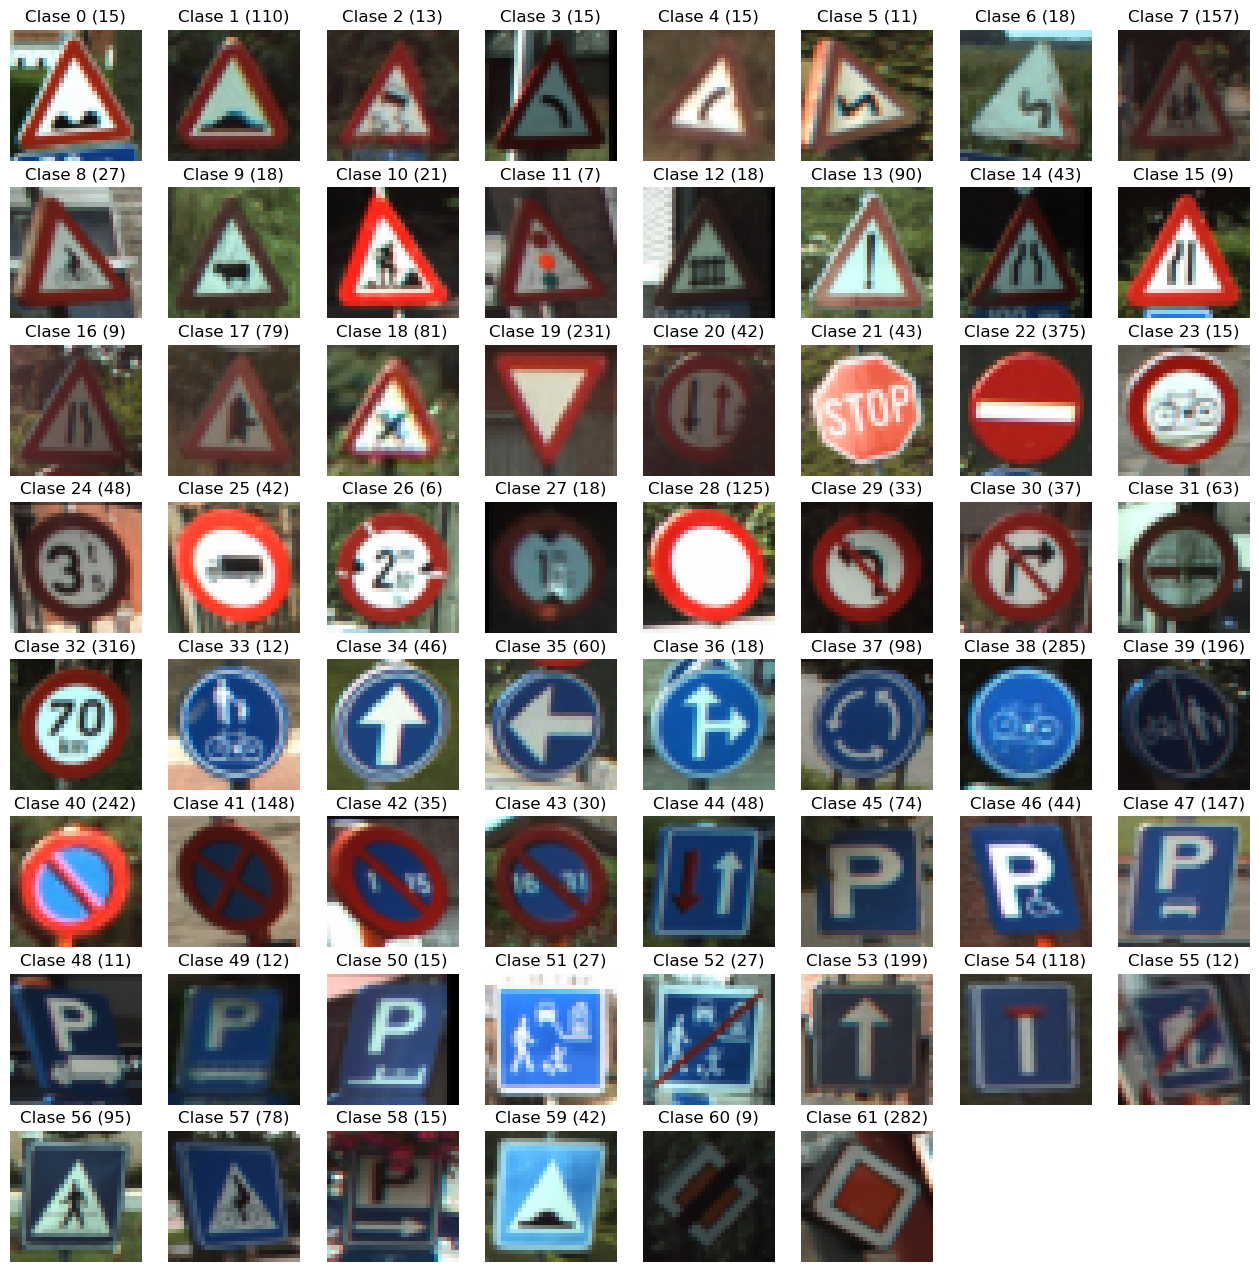

In [85]:
unique_labels = set(labels)
plt.figure(figsize=(16,16))
i = 1

for label in unique_labels:
    temp_im = images[list(labels).index(label)]
    plt.subplot(8,8, i)
    plt.axis("off")
    
    # Opción 1: Corrigiendo el .format() dentro del título
    plt.title("Clase {0} ({1})".format(label, list(labels).count(label)))
    
    # O bien usando un f-string moderno (Opción 2, que es muy limpia):
    # plt.title(f"Clase {label} ({list(labels).count(label)})")
    
    i += 1
    plt.imshow(temp_im)

plt.show()

In [86]:
type(labels)

numpy.ndarray

# Modelo de Red Neuronal con TensorFlow
* Las imagenes no todas son del mismo tamaño
* Hay 62 clases de imagenes (desde la 0 hasta la 61)
* Las distribuciones de señales de trafico no es uniforme (algunas salen mas veces que otras)

In [93]:
from skimage.color import rgb2gray

In [95]:
images_gray = np.array(image)
images_gray = rgb2gray(image)

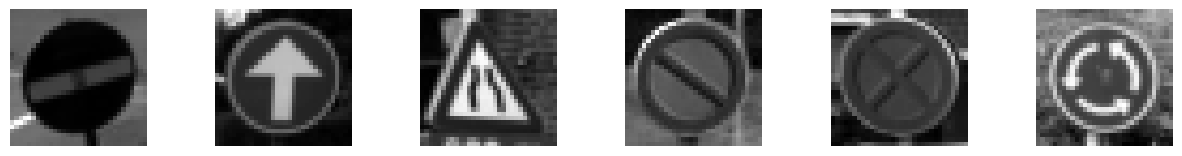

Muestra 0 -> Forma: (32, 32), min: 0.100, max: 0.917
Muestra 1 -> Forma: (32, 32), min: 0.068, max: 0.987
Muestra 2 -> Forma: (32, 32), min: 0.088, max: 0.864
Muestra 3 -> Forma: (32, 32), min: 0.093, max: 0.647
Muestra 4 -> Forma: (32, 32), min: 0.046, max: 0.904
Muestra 5 -> Forma: (32, 32), min: 0.297, max: 0.995


In [99]:
# Convertir todo el conjunto de imágenes a escala de grises
images_gray = np.array([rgb2gray(img) for img in images])

#Ejecutar tu bloque de visualización con normalidad
rand_signs = random.sample(range(0, len(labels)), 6)
plt.figure(figsize=(15, 3))

for i in range(len(rand_signs)):
    temp_im = images_gray[rand_signs[i]]
    plt.subplot(1, 6, i + 1)
    plt.axis("off")
    # Usamos cmap="gray" para que matplotlib renderice correctamente los canales de grises
    plt.imshow(temp_im, cmap="gray")

plt.subplots_adjust(wspace=0.5)
plt.show()

for i in range(len(rand_signs)):
    temp_im = images_gray[rand_signs[i]]
    print(f"Muestra {i} -> Forma: {temp_im.shape}, min: {temp_im.min():.3f}, max: {temp_im.max():.3f}")

In [181]:
# Definir los placeholders usando la capa de compatibilidad de v1
x = tf.compat.v1.placeholder(dtype=tf.float32, shape=[None, 32, 32])
y = tf.compat.v1.placeholder(dtype=tf.int32, shape=[None])

# 1. Reemplazar tf.contrib.layers.flatten por tf.keras.layers.Flatten
flatten_layer = tf.keras.layers.Flatten()
images_flat = flatten_layer(x)

# 2. Reemplazar tf.contrib.layers.fully_connected por tf.keras.layers.Dense
dense_layer = tf.keras.layers.Dense(units=62, activation=tf.nn.relu)
logits = dense_layer(images_flat)

final_pred = tf.argmax(logits, 1)

# Función de pérdida (asegúrate de usar compat.v1 si mantienes la sesión clásica de TF1)
loss = tf.reduce_mean(
    tf.compat.v1.nn.sparse_softmax_cross_entropy_with_logits(
        labels=y, logits=logits
    )
)

# Tasa de aprendizaje típica para Adam (ej. 0.001)
learning_rate = 0.0005

# Optimizador Adam adaptado a TF moderno (v1)
train_opt = tf.compat.v1.train.AdamOptimizer(learning_rate).minimize(loss)

# Compara si la predicción coincide con la etiqueta real (devuelve True o False)
correct_pred = tf.equal(tf.cast(final_pred, tf.int32), y)

# Convierte los booleanos a flotantes (1.0 para aciertos, 0.0 para fallos) y saca la media
accuracy = tf.reduce_mean(tf.cast(correct_pred, tf.float32))

In [182]:
images_flat

<tf.Tensor 'flatten_4_1/Reshape:0' shape=(None, 1024) dtype=float32>

In [183]:
logits

<tf.Tensor 'dense_4_1/Relu:0' shape=(None, 62) dtype=float32>

In [184]:
loss

<tf.Tensor 'Mean_6:0' shape=() dtype=float32>

In [185]:
final_pred

<tf.Tensor 'ArgMax_3:0' shape=(None,) dtype=int64>

In [186]:
tf.set_random_seed(1234)

sess = tf.Session()

sess.run(tf.global_variables_initializer())

for i in range(2001):
    # Una sola ejecución que actualiza el optimizador y extrae ambas métricas a la vez
    _, accuracy_val, loss_val = sess.run(
        [train_opt, accuracy, loss],
        feed_dict={
            x: images_gray,
            y: list(labels),
        },
    )

    if i % 50 == 0:  # Puedes imprimir cada 100 para limpiar un poco la consola
        print(f"EPOCH {i} -> Eficacia: {accuracy_val:.4f}, Pérdidas: {loss_val:.4f}")

EPOCH 0 -> Eficacia: 0.0083, Pérdidas: 4.2531
EPOCH 50 -> Eficacia: 0.3707, Pérdidas: 3.2100
EPOCH 100 -> Eficacia: 0.4962, Pérdidas: 2.7872
EPOCH 150 -> Eficacia: 0.5502, Pérdidas: 2.5461
EPOCH 200 -> Eficacia: 0.5762, Pérdidas: 2.3864
EPOCH 250 -> Eficacia: 0.5961, Pérdidas: 2.2730
EPOCH 300 -> Eficacia: 0.6094, Pérdidas: 2.1868
EPOCH 350 -> Eficacia: 0.6175, Pérdidas: 2.1185
EPOCH 400 -> Eficacia: 0.6219, Pérdidas: 2.0625
EPOCH 450 -> Eficacia: 0.6264, Pérdidas: 2.0156
EPOCH 500 -> Eficacia: 0.6297, Pérdidas: 1.9756
EPOCH 550 -> Eficacia: 0.6330, Pérdidas: 1.9408
EPOCH 600 -> Eficacia: 0.6352, Pérdidas: 1.9102
EPOCH 650 -> Eficacia: 0.6365, Pérdidas: 1.8830
EPOCH 700 -> Eficacia: 0.6380, Pérdidas: 1.8586
EPOCH 750 -> Eficacia: 0.6398, Pérdidas: 1.8366
EPOCH 800 -> Eficacia: 0.6415, Pérdidas: 1.8165
EPOCH 850 -> Eficacia: 0.6417, Pérdidas: 1.7981
EPOCH 900 -> Eficacia: 0.6422, Pérdidas: 1.7812
EPOCH 950 -> Eficacia: 0.6437, Pérdidas: 1.7656
EPOCH 1000 -> Eficacia: 0.6446, Pérdidas: 1

# Evaluacion de la red neuronal

In [187]:
import numpy as np
import random
# 1. Seleccionamos los índices aleatorios
sample_idx = random.sample(range(len(images_gray)), 40)

# 2. Creamos los arrays de NumPy correctamente con su forma tridimensional
sample_images = np.array([images_gray[i] for i in sample_idx])
sample_labels = np.array([labels[i] for i in sample_idx])

In [188]:
# 3. Ejecutamos la predicción sin errores de forma
prediction = sess.run([final_pred], feed_dict={x: sample_images})[0]

In [189]:
prediction

array([ 0, 41, 56,  1, 35, 53,  0, 17, 56, 14,  0, 28, 22,  0, 22,  1, 40,
       41, 31,  7,  7, 22, 39, 40, 38, 38, 53, 57, 31, 22,  0,  1, 57, 28,
       38, 28, 28, 29, 53, 47])

In [190]:
sample_labels

array([19, 41, 56, 59, 35, 54, 32, 17, 56, 14, 19, 59, 22, 32, 22,  1, 40,
       41, 31,  7,  7, 22, 39, 40, 38, 38, 53, 55, 31, 22, 32, 19, 48, 25,
       38,  6, 26, 29, 53, 47])

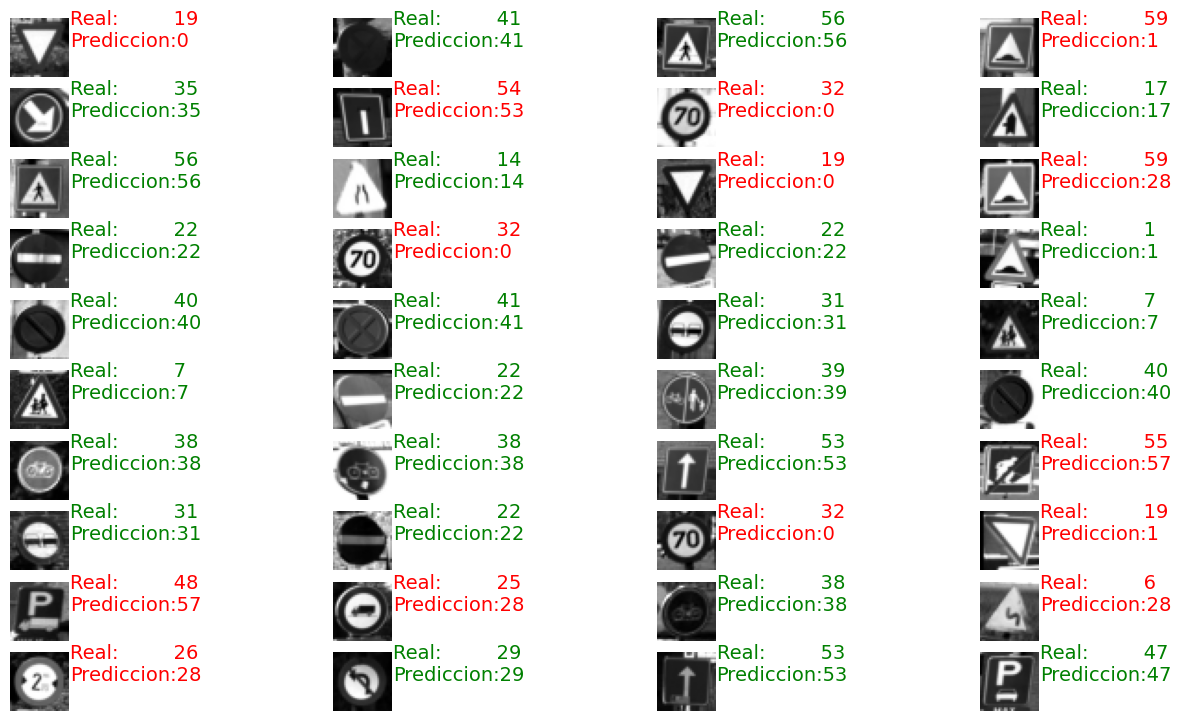

In [191]:
plt.figure(figsize=(16,9))
for i in range(len(sample_images)):
    truth = sample_labels[i]
    predi = prediction[i]
    plt.subplot(10,4,i+1)
    plt.axis("off")
    color = "green" if truth == predi else "red"
    plt.text(32,15, "Real:         {0}\nPrediccion:{1}".format(truth, predi),
            fontsize = 14, color = color)
    plt.imshow(sample_images[i], cmap="gray")
plt.show()

In [192]:
test_images, test_labels = load_ml_data(test_data_dir)

In [193]:
test_images32 = [transform.resize(im, (32,32)) for im in test_images]

In [194]:
test_images32 = rgb2gray(np.array(test_images32))

In [195]:
prediction = sess.run([final_pred], feed_dict={x:test_images32})[0]

In [196]:
match_count = sum(lt == lp for lt, lp in zip(test_labels, prediction))
match_count

np.int64(1322)

In [197]:
acc = match_count/len(test_labels)*100
print("Eficacia de la red neuronal: {:.3f}".format(acc))

Eficacia de la red neuronal: 52.460
